# Лабораторная работа №3: Кластерный анализ методом DBSCAN
**Студент:** Любецкая Антонина  
**Цель исследования:** Провести кластеризацию 48 городов мира методом DBSCAN по экономическим показателям (часы работы, индекс цен, индекс зарплат), подобрать и обосновать параметры `eps` и `min_samples`, выделить основные кластеры и отдельно разобрать города, которые алгоритм отнес к шуму.  
**Гипотеза:** В прошлых работах (иерархический анализ и k-means) алгоритмы обязательно распределяли все 48 городов по кластерам, даже если какой-то город сильно выбивался из общей картины. Метод DBSCAN работает от плотности точек, поэтому он должен выделить те же 3 основные группы городов, но самые нестандартные города (например, слишком дорогие или с огромными переработками) вынесет в шум (`-1`).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN, KMeans
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

In [2]:
plt.style.use('ggplot')
%matplotlib inline

# Шаг 1: Загрузка и подготовка данных
Здесь все делаем так же, как в первой и второй лабораторных: загружаем файл, меняем заглушки `-9999` на `NaN` и переводим строки с запятыми в обычные числа `float`. Пропуски у Каира и Джакарты заполняем медианой, чтобы оставить в выборке все 48 городов и потом сравнить результаты с k-means.

In [3]:
df_raw = pd.read_csv("Econom_Cities_data.csv", sep=';', index_col='City')

# Убираем заглушки -9999 и переводим колонки в числа
df_clean = df_raw.replace([-9999, '-9999'], np.nan)
df_clean['Price'] = pd.to_numeric(df_clean['Price'].astype(str).str.replace(',', '.'), errors='coerce')
df_clean['Salary'] = pd.to_numeric(df_clean['Salary'].astype(str).str.replace(',', '.'), errors='coerce')

print("Города с пропусками в данных:")
print(df_clean[df_clean.isna().any(axis=1)])

Города с пропусками в данных:
         Work  Price  Salary
City                        
Cairo     NaN   37.1     NaN
Jakarta   NaN   43.6     NaN


In [4]:
# Заполняем пропуски медианой
df = df_clean.fillna(df_clean.median(numeric_only=True))

**Зачем нужно масштабирование:**  
DBSCAN ищет соседей вокруг каждой точки в заданном радиусе `eps` с помощью обычного **евклидова расстояния**. Так как рабочие часы (`Work`) измеряются тысячами (от 1583 до 2375), а цены и зарплаты (`Price`, `Salary`) — десятками, без масштабирования расстояние между городами будет считаться почти только по часам работы. Поэтому обязательно стандартизируем данные через `StandardScaler`.

In [5]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df)
df_scaled = pd.DataFrame(X_scaled, columns=df.columns, index=df.index)
df_scaled.head()

,Work,Price,Salary
City,,,
Amsterdam,-0.974577,-0.151250,0.387038
Athens,-0.512818,-0.698647,-0.388428
Bogota,1.618375,-1.436242,-1.176402
Bombay,1.026377,-1.788804,-1.434891
Brussels,-1.010097,0.229145,0.449576


# Шаг 2: Подбор параметров `min_samples` и `eps`
В DBSCAN нам не нужно заранее указывать количество кластеров — алгоритм определяет его сам. Но результат напрямую зависит от двух настроек:
1. **`min_samples`** — сколько минимум точек должно быть рядом (включая сам город), чтобы это место считалось плотным центром кластера (ядровой точкой). Обычно для небольших таблиц берут значение от $D + 1$ до $2D$, где $D$ — количество признаков. У нас 3 признака (`Work`, `Price`, `Salary`), поэтому логично проверить значения **4, 5 и 6**.
2. **`eps` (эпсилон)** — радиус вокруг точки, в котором мы ищем этих соседей.

Чтобы подобрать радиус `eps` не наугад, построим **график k-расстояний (k-distance plot)**. Для каждого города посчитаем расстояние до его $k$-го ближайшего соседа и отсортируем эти расстояния по возрастанию. Нам нужно найти место на графике, где плавная линия начинает резко уходить вверх (точка изгиба). До этого изгиба лежат города из плотных групп, а после него — далекие одиночные точки (будущий шум).

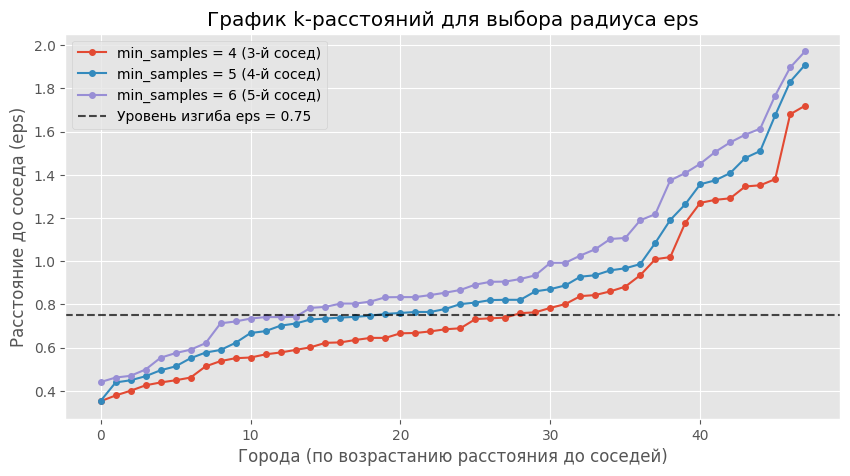

In [6]:
plt.figure(figsize=(10, 5))

for m in [4, 5, 6]:
    # Находим расстояния до m ближайших соседей (индекс m-1 берем потому, что 0-й сосед — это сама точка)
    neighbors = NearestNeighbors(n_neighbors=m)
    neighbors_fit = neighbors.fit(X_scaled)
    distances, indices = neighbors_fit.kneighbors(X_scaled)
    
    # Сортируем расстояния по возрастанию для графика
    k_distances = np.sort(distances[:, m - 1])
    plt.plot(k_distances, marker='o', markersize=4, label=f'min_samples = {m} ({m-1}-й сосед)')

plt.axhline(y=0.75, color='black', linestyle='--', alpha=0.7, label='Уровень изгиба eps = 0.75')
plt.title('График k-расстояний для выбора радиуса eps')
plt.xlabel('Города (по возрастанию расстояния до соседей)')
plt.ylabel('Расстояние до соседа (eps)')
plt.legend()
plt.grid(True)
plt.show()

**Что видно по графику и как выбрать точные значения:**  
На графике видно, что для всех трех линий (`min_samples = 4, 5, 6`) перегиб находится примерно в районе **`eps` от `0.65` до `0.85`**. После уровня `0.75–0.85` графики резко идут вверх (расстояния прыгают выше 1.0) — там начинаются города-выбросы.

Напишем функцию, которая переберет разные комбинации `eps` и `min_samples` из этого интервала и выведет таблицу: сколько получается кластеров, сколько городов уходит в шум и какой при этом коэффициент силуэта (он считается только по кластерам, без учета шума).

In [7]:
def check_dbscan_params(X, eps_list, min_samples_list):
    results = []
    for m in min_samples_list:
        for eps in eps_list:
            model = DBSCAN(eps=eps, min_samples=m, metric='euclidean')
            labels = model.fit_predict(X)
            
            # Считаем число кластеров (без учета метки шума -1)
            n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
            n_noise = list(labels).count(-1)
            noise_pct = round(n_noise / len(X) * 100, 1)
            
            # Силуэт считаем только для городов внутри кластеров (если кластеров хотя бы 2)
            mask = labels != -1
            if n_clusters >= 2:
                sil = round(silhouette_score(X[mask], labels[mask]), 3)
            else:
                sil = None
                
            # Сколько городов попало в каждый кластер
            cluster_sizes = {int(k) + 1: int(v) for k, v in pd.Series(labels[mask]).value_counts().items()}
            
            results.append({
                'min_samples': m,
                'eps': round(eps, 2),
                'Число кластеров': n_clusters,
                'Шум (городов)': n_noise,
                'Шум (%)': noise_pct,
                'Silhouette (без шума)': sil,
                'Размеры кластеров': str(cluster_sizes)
            })
    return pd.DataFrame(results)

grid_df = check_dbscan_params(X_scaled, eps_list=[0.65, 0.70, 0.75, 0.80, 0.85], min_samples_list=[4, 5, 6])
grid_df

,min_samples,eps,Число кластеров,Шум (городов),Шум (%),Silhouette (без шума),Размеры кластеров
0,4,0.65,3,17,35.4,0.380,"{1: 16, 3: 11, 2: 4}"
1,4,0.70,3,13,27.1,0.368,"{1: 16, 3: 14, 2: 5}"
2,4,0.75,2,10,20.8,0.506,"{2: 20, 1: 18}"
3,4,0.80,2,9,18.8,0.495,"{2: 20, 1: 19}"
4,4,0.85,2,8,16.7,0.484,"{2: 21, 1: 19}"
5,5,0.65,2,27,56.2,0.682,"{1: 15, 2: 6}"
6,5,0.70,3,24,50.0,0.578,"{1: 15, 2: 6, 3: 3}"
7,5,0.75,3,12,25.0,0.460,"{1: 18, 2: 10, 3: 8}"
8,5,0.80,2,10,20.8,0.506,"{2: 20, 1: 18}"
9,5,0.85,2,9,18.8,0.494,"{2: 21, 1: 18}"


**Обоснование выбора `eps = 0.75` и `min_samples = 5`:**  
Посмотрим на таблицу и разберем, почему другие варианты подходят хуже:
* **Почему не берем маленькие `eps = 0.65–0.70` (при `min_samples = 5, 6`):** радиус слишком маленький, поэтому от 24 до 29 городов из 48 (больше половины!) улетают в шум.
* **Почему не берем большие `eps = 0.80–0.85`:** при таком радиусе остается всего **2 кластера**. Все развивающиеся города сливаются в одну большую группу на 20 городов. Как и при $k=2$ в прошлой работе, мы теряем важное разделение развивающихся стран по количеству рабочих часов.
* **Почему выбираем `eps = 0.75` и `min_samples = 5`:**
  1. Алгоритм выделяет **3 понятных кластера** (на 18, 10 и 8 городов), которые по смыслу отлично совпадают с тремя группами из прошлых лабораторных.
  2. Если сравнить с `min_samples = 4` (при `eps = 0.70`), то там силуэт заметно ниже (`0.368`), а один из кластеров совсем маленький (5 городов). При `min_samples = 5` и `eps = 0.75` кластеры ровнее, а **коэффициент силуэта равен `0.460`** (это даже выше, чем `0.383` в k-means, так как самые крайние города ушли в шум и перестали портить четкость групп).
  3. В шум попадает **12 городов (25%)** — это как раз самые нестандартные города мира, которые интересно разобрать отдельно.

# Шаг 3: Обучение модели и разделение точек на Ядро, Границу и Шум
Во второй лабораторной для k-means мы находили центроиды кластеров. В DBSCAN центроидов нет, но зато все точки делятся на три типа:
* **Ядровые точки (Core)** — это плотный центр каждого кластера (рядом с ними в радиусе `0.75` есть минимум 5 соседей). В `sklearn` их номера лежат в `dbscan.core_sample_indices_`.
* **Граничные точки (Border)** — города на краю кластера (вокруг них самих меньше 5 соседей, но они попали в радиус какого-то ядрового города).
* **Шум (Noise, метка `-1`)** — города-выбросы, которые лежат далеко от всех групп.

In [8]:
# Обучаем DBSCAN с выбранными параметрами
dbscan = DBSCAN(eps=0.75, min_samples=5, metric='euclidean')
labels = dbscan.fit_predict(X_scaled)

# Сделаем нумерацию кластеров с 1 (1, 2, 3), а шум оставим -1
df['Cluster'] = [l + 1 if l != -1 else -1 for l in labels]

# Запишем для каждого города, какая он точка: Ядро, Граница или Шум
df['Point_Type'] = 'Border (Граница)'
df.iloc[dbscan.core_sample_indices_, df.columns.get_loc('Point_Type')] = 'Core (Ядро)'
df.loc[df['Cluster'] == -1, 'Point_Type'] = 'Noise (Шум)'

print("Сколько всего получилось точек каждого типа:")
print(df['Point_Type'].value_counts())
print()
print("Распределение типов точек внутри кластеров:")
print(pd.crosstab(df['Cluster'], df['Point_Type']))

Сколько всего получилось точек каждого типа:
Point_Type
Core (Ядро)         19
Border (Граница)    17
Noise (Шум)         12
Name: count, dtype: int64

Распределение типов точек внутри кластеров:
Point_Type  Border (Граница)  Core (Ядро)  Noise (Шум)
Cluster                                               
-1                         0            0           12
 1                         5           13            0
 2                         6            4            0
 3                         6            2            0


# Шаг 4: Визуализация на графиках Scatter Plot (3D и 2D)
Построим два графика рассеяния, как во второй лабораторной, но вместо центроидов выделим особенности DBSCAN:
1. На **3D Scatter Plot** в исходных признаках покажем 3 кластера разными цветами, а города из шума (`-1`) нарисуем большими красными крестиками и подпишем.
2. На **2D Scatter Plot (через PCA)** покажем структуру групп: **ядровые города** нарисуем крупными кругами, **граничные города** — треугольниками поменьше, а **шум** — красными крестиками.

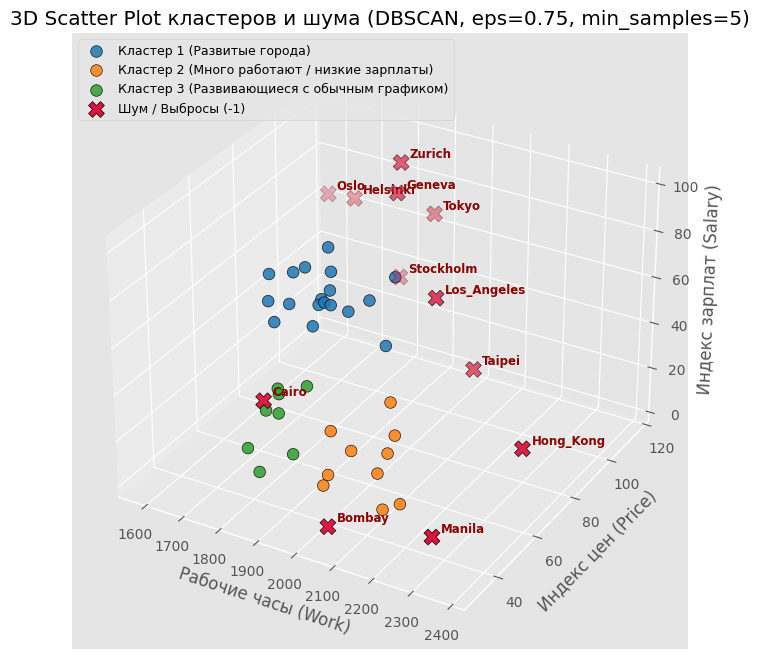

In [9]:
# 3D Scatter Plot в исходных признаках
fig = plt.figure(figsize=(11, 8))
ax = fig.add_subplot(111, projection='3d')

colors = {1: '#1f77b4', 2: '#ff7f0e', 3: '#2ca02c'}
names = {
    1: 'Кластер 1 (Развитые города)',
    2: 'Кластер 2 (Много работают / низкие зарплаты)',
    3: 'Кластер 3 (Развивающиеся с обычным графиком)'
}

# Рисуем 3 кластера
for c in [1, 2, 3]:
    sub = df[df['Cluster'] == c]
    ax.scatter(sub['Work'], sub['Price'], sub['Salary'],
               c=colors[c], s=70, edgecolor='k', alpha=0.85, label=names[c])

# Отдельно рисуем шум (-1) красными крестиками
noise_df = df[df['Cluster'] == -1]
ax.scatter(noise_df['Work'], noise_df['Price'], noise_df['Salary'],
           c='crimson', marker='X', s=130, edgecolor='black', label='Шум / Выбросы (-1)')

# Подпишем все города, которые попали в шум
for city in noise_df.index:
    ax.text(noise_df.loc[city, 'Work'] + 15,
            noise_df.loc[city, 'Price'] + 1.5,
            noise_df.loc[city, 'Salary'] + 1.5,
            city, fontsize=8.5, fontweight='bold', color='darkred')

ax.set_title('3D Scatter Plot кластеров и шума (DBSCAN, eps=0.75, min_samples=5)')
ax.set_xlabel('Рабочие часы (Work)')
ax.set_ylabel('Индекс цен (Price)')
ax.set_zlabel('Индекс зарплат (Salary)')
ax.legend(loc='upper left', fontsize=9)
plt.show()

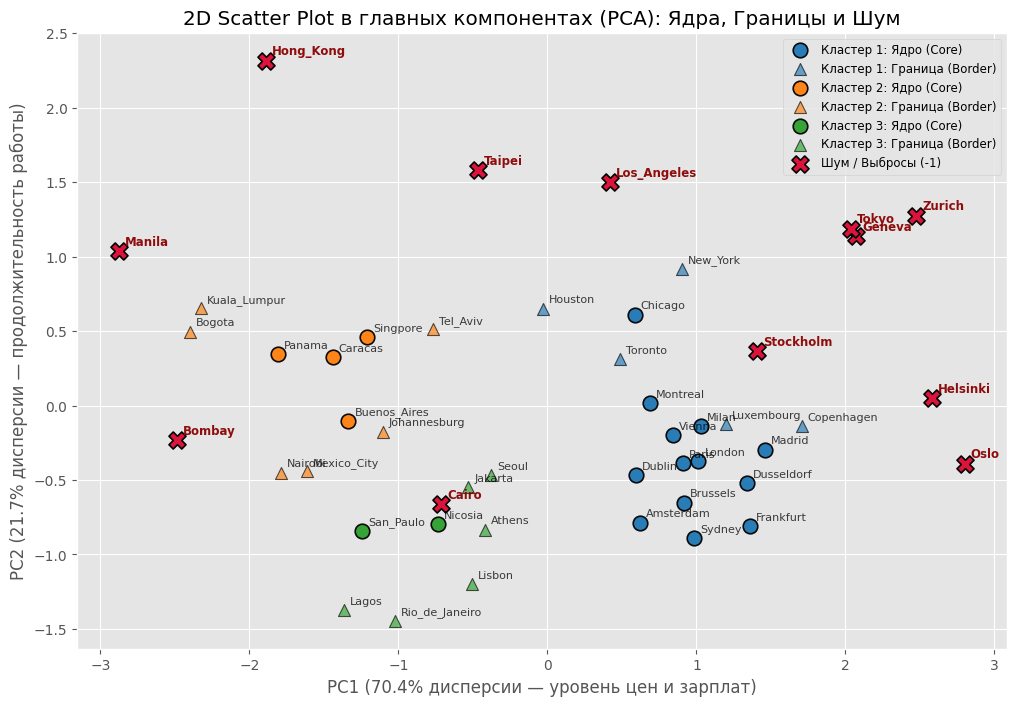

In [10]:
# 2D Scatter Plot с помощью PCA: выделяем Ядро (Core), Границу (Border) и Шум (Noise)
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)
df['PC1'] = X_pca[:, 0]
df['PC2'] = X_pca[:, 1]

plt.figure(figsize=(12, 8))

for c in [1, 2, 3]:
    # Ядровые города — большие круги
    core_pts = df[(df['Cluster'] == c) & (df['Point_Type'] == 'Core (Ядро)')]
    plt.scatter(core_pts['PC1'], core_pts['PC2'], c=colors[c], marker='o',
                s=110, edgecolor='black', linewidth=1.2, alpha=0.95, label=f'Кластер {c}: Ядро (Core)')
    
    # Граничные города — треугольники
    border_pts = df[(df['Cluster'] == c) & (df['Point_Type'] == 'Border (Граница)')]
    plt.scatter(border_pts['PC1'], border_pts['PC2'], c=colors[c], marker='^',
                s=75, edgecolor='black', linewidth=0.8, alpha=0.65, label=f'Кластер {c}: Граница (Border)')

# Города из шума — красные крестики
noise_pts = df[df['Cluster'] == -1]
plt.scatter(noise_pts['PC1'], noise_pts['PC2'], c='crimson', marker='X',
            s=150, edgecolor='black', linewidth=1.2, label='Шум / Выбросы (-1)')

# Подпишем города на графике
for city in df.index:
    is_noise = df.loc[city, 'Cluster'] == -1
    plt.annotate(city,
                 (df.loc[city, 'PC1'] + 0.04, df.loc[city, 'PC2'] + 0.04),
                 fontsize=8.5 if is_noise else 8,
                 fontweight='bold' if is_noise else 'normal',
                 color='darkred' if is_noise else 'black',
                 alpha=0.95 if is_noise else 0.75)

plt.title('2D Scatter Plot в главных компонентах (PCA): Ядра, Границы и Шум')
plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% дисперсии — уровень цен и зарплат)')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% дисперсии — продолжительность работы)')
plt.legend(loc='best', fontsize=8.5)
plt.grid(True)
plt.show()

# Шаг 5: Интерпретация кластеров и разбор городов из шума
Посчитаем средние значения показателей для каждого кластера и посмотрим, какие города вошли в ядро и на границу каждой группы.

In [11]:
# Средние значения по кластерам и шуму
cluster_summary = df.groupby('Cluster')[['Work', 'Price', 'Salary']].mean().round(1)
cluster_summary['Всего городов'] = df['Cluster'].value_counts()
cluster_summary['Ядро (Core)'] = df[df['Point_Type'] == 'Core (Ядро)'].groupby('Cluster').size()
cluster_summary['Граница (Border)'] = df[df['Point_Type'] == 'Border (Граница)'].groupby('Cluster').size()
cluster_summary = cluster_summary.fillna(0).astype({'Ядро (Core)': int, 'Граница (Border)': int})
print("Средние показатели по группам:")
cluster_summary

Средние показатели по группам:


,Work,Price,Salary,Всего городов,Ядро (Core),Граница (Border)
Cluster,,,,,,
-1,1953.3,82.2,50.7,12,0,0
1,1776.7,77.4,54.6,18,13,5
2,2031.3,52.5,13.7,10,4,6
3,1805.1,50.0,22.3,8,2,6


In [12]:
# Список городов в каждом кластере (отдельно ядро и граница)
for c in [1, 2, 3]:
    core_list = df[(df['Cluster'] == c) & (df['Point_Type'] == 'Core (Ядро)')].index.tolist()
    border_list = df[(df['Cluster'] == c) & (df['Point_Type'] == 'Border (Граница)')].index.tolist()
    print(f"Кластер {c} (всего {len(core_list) + len(border_list)} городов):")
    print(f"  Ядро ({len(core_list)}): {', '.join(core_list)}")
    print(f"  Граница ({len(border_list)}): {', '.join(border_list)}")
    print()

Кластер 1 (всего 18 городов):
  Ядро (13): Amsterdam, Brussels, Chicago, Dublin, Dusseldorf, Frankfurt, London, Madrid, Milan, Montreal, Paris, Sydney, Vienna
  Граница (5): Copenhagen, Houston, Luxembourg, New_York, Toronto

Кластер 2 (всего 10 городов):
  Ядро (4): Buenos_Aires, Caracas, Panama, Singpore
  Граница (6): Bogota, Johannesburg, Kuala_Lumpur, Mexico_City, Nairobi, Tel_Aviv

Кластер 3 (всего 8 городов):
  Ядро (2): Nicosia, San_Paulo
  Граница (6): Athens, Jakarta, Lagos, Lisbon, Rio_de_Janeiro, Seoul



### Отдельный разбор объектов, попавших в шум (`Cluster = -1`)
В шум попали **12 городов**. Выведем таблицу с их показателями, чтобы понять, чем именно они отличаются от остальных и почему алгоритм не включил их ни в один кластер.

In [13]:
noise_cities = df[df['Cluster'] == -1][['Work', 'Price', 'Salary']].sort_values(by='Salary', ascending=False)
print("Города, которые DBSCAN отнес к шуму (-1):")
noise_cities

Города, которые DBSCAN отнес к шуму (-1):


,Work,Price,Salary
City,,,
Zurich,1868.0,100.0,100.00
Geneva,1880.0,95.9,90.30
Tokyo,1880.0,115.0,68.00
Helsinki,1667.0,113.6,66.60
Los_Angeles,2068.0,79.8,65.20
Oslo,1583.0,115.5,63.70
Cairo,1849.0,37.1,43.65
Stockholm,1805.0,111.3,39.20
Taipei,2145.0,84.3,34.50


**Почему эти 12 городов попали в шум:**  
Если посмотреть на цифры в таблице, то видно, что все эти города — не случайная ошибка, а реальные крайности по одному или сразу нескольким признакам. Их можно разделить на 4 простые группы:

1. **Самые богатые города мира (`Zurich`, `Geneva`):**  
   * В Цюрихе (`Salary = 100`) и Женеве (`Salary = 90.3`) зарплаты почти в два раза выше, чем в среднем по развитым городам из Кластера 1 (`Salary = 54.6`). В k-means они входили в общий богатый кластер, но в DBSCAN они лежат слишком далеко от обычных европейских столиц.
2. **Слишком дорогие города Скандинавии и Токио (`Oslo`, `Helsinki`, `Tokyo`, `Stockholm`):**  
   * У этих четырех городов самые высокие цены во всей таблице (`Price` от `111.3` до `115.5` — даже выше, чем в Цюрихе!), но зарплаты при этом заметно ниже швейцарских (`39.2–68.0`). Плюс в **Осло** люди работают меньше всех в мире (`1583` часа в год), а в **Стокгольме** слишком большой разрыв между высокими ценами (`111.3`) и средней зарплатой (`39.2`).
3. **Богатые города, но с огромными переработками (`Los_Angeles`, `Taipei`):**  
   * **Лос-Анджелес** по ценам (`79.8`) и зарплате (`65.2`) похож на развитые города из Кластера 1, но работают там намного больше (`2068` часов против `1776.7` в Европе), поэтому он не дотянулся до первого кластера.  
   * **Тайбэй** (`Work = 2145`, `Price = 84.3`, `Salary = 34.5`) застрял ровно между группами: для бедных стран с переработками он слишком дорогой и обеспеченный, а для развитых западных стран там слишком много работают.
4. **Рекорды по переработкам, бедности и особенность Каира (`Hong_Kong`, `Manila`, `Bombay`, `Cairo`):**  
   * **Гонконг** (`2375` часов) и **Манила** (`2268` часов и зарплата всего `4.0`) — это абсолютные рекорды по длительности рабочего года во всем датасете, они лежат далеко даже от работящего Кластера 2 (`2031.3` ч).  
   * **Бомбей** (`Price = 30.3`, `Salary = 5.3`) — самый дешевый город в выборке.  
   * **Каир** (`Work = 1849`, `Price = 37.1`, `Salary = 43.65`) — попал в шум из-за того, как мы заполняли пропуски! Изначально у него стояли `-9999` в часах и зарплате. Когда мы заменили пропуск общей медианой по всем городам, Каир получил довольно высокую зарплату (`43.65`) при своей очень низкой цене (`37.1`). В реальности городов с такими низкими ценами и такой высокой зарплатой в таблице больше нет, и DBSCAN сразу заметил эту неестественную точку.

### Сравнение результатов DBSCAN и K-Means (из Лабораторной работы №2)
Сделаем общую таблицу пересечений, чтобы посмотреть, из каких кластеров k-means ($k=3$) города перешли в кластеры и шум DBSCAN.

In [14]:
kmeans_model = KMeans(n_clusters=3, random_state=42, n_init=10)
df['KMeans_Cluster'] = kmeans_model.fit_predict(X_scaled) + 1

comparison = pd.crosstab(df['KMeans_Cluster'], df['Cluster'],
                         rownames=['Кластеры K-Means (Лаб 2)'],
                         colnames=['Кластеры DBSCAN (Лаб 3)'])
print("Куда перешли города из кластеров K-Means в модели DBSCAN:")
comparison

Куда перешли города из кластеров K-Means в модели DBSCAN:


Кластеры DBSCAN (Лаб 3),-1,1,2,3
Кластеры K-Means (Лаб 2),,,,
1,1,0,4,8
2,7,18,0,0
3,4,0,6,0


## Выводы по работе
В третьей лабораторной работе мы провели кластеризацию 48 городов мира методом **DBSCAN** и сравнили ее с прошлыми результатами:

1. **Подбор параметров:**  
   Исходя из числа признаков ($D=3$) и графика k-расстояний мы выбрали параметры **`eps = 0.75`** и **`min_samples = 5`**. С этими настройками алгоритм сам разделил города на **3 кластера** (36 городов) и выделил 12 городов в шум. При этом коэффициент силуэта по кластерам составил **0.460** — это лучше, чем было в методе k-means (0.383), потому что крайние нестандартные города ушли в шум и группы стали более компактными.

2. **Интерпретация полученных кластеров:**  
   * **Кластер 1 — Развитые города с высоким уровнем жизни (18 городов: 13 в ядре, 5 на границе):** *Amsterdam, Brussels, Chicago, Dublin, Frankfurt, London, Milan, Paris, Vienna, New York и др.* Здесь меньше всего работают (`1776.7` ч), но получают высокие зарплаты (`54.6`) при высоких ценах (`77.4`).
   * **Кластер 2 — Индустриальные города с большими переработками (10 городов: 4 в ядре, 6 на границе):** *Buenos Aires, Caracas, Panama, Singpore, Bogota, Kuala Lumpur, Tel Aviv и др.* Люди здесь работают очень много (`2031.3` ч в год), но зарплаты самые низкие (`13.7`), а цены средние (`52.5`).
   * **Кластер 3 — Развивающиеся города с нормальным графиком работы (8 городов: 2 в ядре, 6 на границе):** *Nicosia, San Paulo, Athens, Lisbon, Rio de Janeiro, Seoul и др.* Недорогие города (`Price = 50.0`) с небольшими зарплатами (`22.3`), но без переработок (`1805.1` ч в год — почти как в Европе).

3. **Что дал анализ шума и сравнение с прошлыми работами:**  
   Таблица сравнения с k-means показала, что все три метода кластеризации находят одни и те же 3 типа экономики. Но если иерархический метод и k-means были обязаны приписать каждый город к какой-то группе (например, объединяли Цюрих, Токио и Лос-Анджелес с обычными европейскими городами), то DBSCAN отделил 12 городов-выбросов в шум (`-1`). Благодаря этому мы смогли отдельно увидеть самые богатые города (*Zurich, Geneva*), самые дорогие столицы (*Oslo, Helsinki, Tokyo, Stockholm*), города с рекордными переработками (*Hong Kong, Manila*), а также заметили искажение данных у *Cairo* после замены пропусков медианой.